# Proyek Akhir Belajar Fundamental Deep Learning: Klasifikasi Varietas Beras
**Nama**: Endros  
**Dataset**: Rice Image Dataset  
**Target**: Klasifikasi Varietas Beras dengan CNN (>85% Akurasi)

## 1. Import Library & Setup Environment

In [1]:
import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

# Setup Environment & Patching NumPy untuk TFJS
if not hasattr(np, 'object'):
    np.object = object
if not hasattr(np, 'bool'):
    np.bool = bool

os.environ['PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION'] = 'python'

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

# Instalasi library pendukung & setuptools untuk mengatasi error distutils
!pip install -q setuptools kagglehub split-folders tensorflowjs

import kagglehub
import splitfolders

print("1. Seluruh Library & Setup Environment Berhasil Dimuat.")

/tmp/ipykernel_2460/4080358965.py:9: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, 'object'):


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigquery-magics 0.14.0 requires packaging>=24.2.0, but you have packaging 20.9 which is incompatible.
google-cloud-bigquery 3.46.2 requires packaging>=24.2.0, but you have packaging 20.9 which is incompatible.
langchain-core 1.7.0 requires packaging>=23.2.0, but you have packaging 20.9 which is incompatible.
scikit-image 0.25.2 requires packaging>=21, but you have packaging 20.9 which is incompatible.
xarray 2025.12.0 requires packaging>=24.1, but you have packaging 20.9 which is incompatible.
jupyter-server 2.20.0 requires packaging>=22.0, but you have packaging 20.9 which is incompatible.
pysal 25.7 requires packaging>=22, but you have packaging 20.9 which is incompatible.
google

## 2. Load Dataset, Pengecekan Data, & Pembagian Data (Train, Validation, Test)

Mengunduh Rice Image Dataset...
Using Colab cache for faster access to the 'rice-image-dataset' dataset.


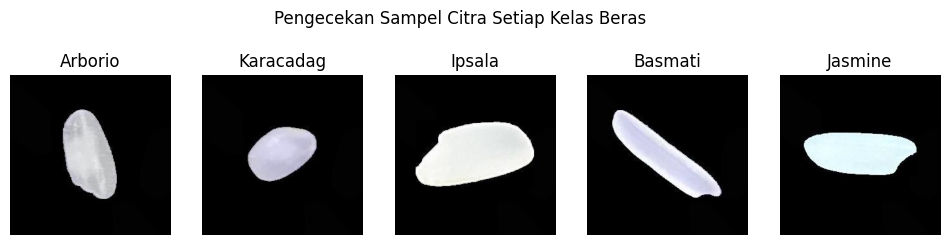

Membagi dataset ke folder 'dataset_split'...


Copying files: 75000 files [00:16, 4480.54 files/s]

Pembagian dataset selesai.


In [2]:
# 1. Unduh Dataset dari Kaggle
print("Mengunduh Rice Image Dataset...")
path = kagglehub.dataset_download("muratkokludataset/rice-image-dataset")

source_folder = os.path.join(path, "Rice_Image_Dataset")
target_folder = "/tmp/Rice_Image_Dataset"

if os.path.exists(target_folder):
    !rm -rf /tmp/Rice_Image_Dataset

!cp -r "$source_folder" "$target_folder"

citation_file = os.path.join(target_folder, 'Rice_Citation_Request.txt')
if os.path.exists(citation_file):
    os.remove(citation_file)

# 2. Visualisasi Pengecekan Dataset (Saran Reviewer)
classes = [d for d in os.listdir(target_folder) if os.path.isdir(os.path.join(target_folder, d))]
plt.figure(figsize=(12, 3))
for i, cls in enumerate(classes):
    cls_folder = os.path.join(target_folder, cls)
    img_name = os.listdir(cls_folder)[0]
    img_path = os.path.join(cls_folder, img_name)
    img = Image.open(img_path)
    plt.subplot(1, len(classes), i+1)
    plt.imshow(img)
    plt.title(cls)
    plt.axis('off')
plt.suptitle("Pengecekan Sampel Citra Setiap Kelas Beras")
plt.show()

# 3. Pembagian Dataset (80% Train, 10% Val, 10% Test)
print("Membagi dataset ke folder 'dataset_split'...")
splitfolders.ratio(target_folder, output="dataset_split", seed=42, ratio=(.8, .1, .1))
print("Pembagian dataset selesai.")

## 3. Data Preprocessing & ImageDataGenerator

In [3]:
train_dir = 'dataset_split/train'
val_dir = 'dataset_split/val'
test_dir = 'dataset_split/test'

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    horizontal_flip=True,
    shear_range=0.2,
    fill_mode='nearest'
)
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir, target_size=(150, 150), batch_size=32, class_mode='categorical'
)
val_generator = val_datagen.flow_from_directory(
    val_dir, target_size=(150, 150), batch_size=32, class_mode='categorical'
)
test_generator = test_datagen.flow_from_directory(
    test_dir, target_size=(150, 150), batch_size=32, class_mode='categorical', shuffle=False
)

Found 60000 images belonging to 5 classes.
Found 7500 images belonging to 5 classes.
Found 7500 images belonging to 5 classes.


## 4. Pembangunan Arsitektur Model Sequential CNN

In [4]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 3)),
    MaxPooling2D(2, 2),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(5, activation='softmax') # 5 kelas jenis beras
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    18,940,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,036,229 (72.62 MB)

 Trainable params: 19,036,229 (72.62 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Pelatihan Model dengan Callback

In [5]:
class MyCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        if logs.get('accuracy') > 0.98 and logs.get('val_accuracy') > 0.98:
            print("\nAkurasi training dan validasi sudah mencapai > 98%!")
            self.model.stop_training = True

callbacks = MyCallback()

history = model.fit(
    train_generator,
    steps_per_epoch=100,
    epochs=10,
    validation_data=val_generator,
    validation_steps=30,
    callbacks=[callbacks]
)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 240s 2s/step - accuracy: 0.8200 - loss: 0.5175 - val_accuracy: 0.9500 - val_loss: 0.1380
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 220s 2s/step - accuracy: 0.9334 - loss: 0.1834 - val_accuracy: 0.9396 - val_loss: 0.1673
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 229s 2s/step - accuracy: 0.9456 - loss: 0.1692 - val_accuracy: 0.9594 - val_loss: 0.1131
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 220s 2s/step - accuracy: 0.9472 - loss: 0.1425 - val_accuracy: 0.9729 - val_loss: 0.0765
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 262s 3s/step - accuracy: 0.9513 - loss: 0.1340 - val_accuracy: 0.9510 - val_loss: 0.1264
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 262s 3s/step - accuracy: 0.9603 - loss: 0.1352 - val_accuracy: 0.9563 - val_loss: 0.1360
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 221s 2s/step - accuracy: 0.9556 - loss: 0.1394 - val_accuracy: 0.9677 - val_loss: 0.0834
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 219s 2s/step - accuracy: 0.9559 - loss: 0.1241 - val_accu

## 6. Visualisasi Akurasi dan Loss

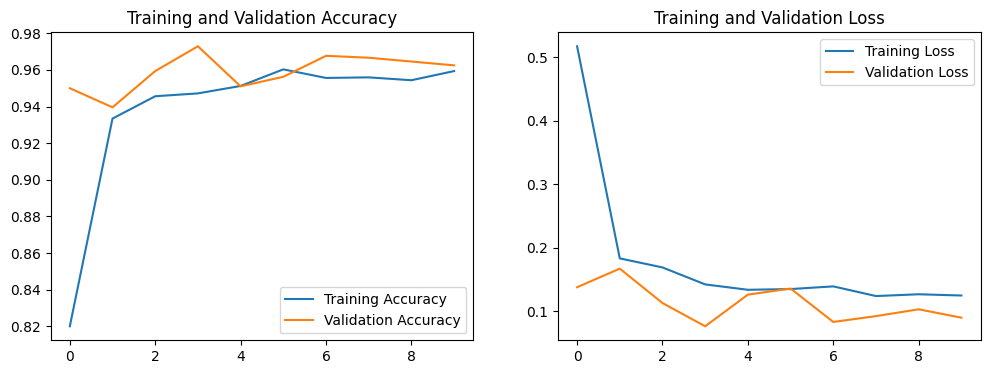

In [6]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')

plt.show()

## 7. Evaluasi Model pada Data Uji (Test Set)

In [7]:
test_loss, test_acc = model.evaluate(test_generator)

print("\n" + "="*40)
print("[HASIL EVALUASI MODEL PADA TEST SET]")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc * 100:.2f}%")
print("="*40)

235/235 ━━━━━━━━━━━━━━━━━━━━ 121s 516ms/step - accuracy: 0.9671 - loss: 0.0997

[HASIL EVALUASI MODEL PADA TEST SET]
Test Loss     : 0.0997
Test Accuracy : 96.71%


## 8. Export Model ke Format SavedModel, TF-Lite, dan TFJS

In [15]:
import os
import json
import struct
import numpy as np
import tensorflow as tf

# 1. Export ke SavedModel (.pb)
saved_model_dir = "saved_model"
model.export(saved_model_dir)
print("1. SavedModel berhasil disimpan di:", saved_model_dir)

# 2. Export ke TF-Lite (.tflite)
tflite_dir = "tflite"
os.makedirs(tflite_dir, exist_ok=True)
converter = tf.lite.TFLiteConverter.from_saved_model(saved_model_dir)
tflite_model = converter.convert()

tflite_model_path = os.path.join(tflite_dir, "model.tflite")
with open(tflite_model_path, "wb") as f:
    f.write(tflite_model)
print("2. Model TF-Lite berhasil disimpan di:", tflite_model_path)

# Simpan label kelas untuk TFLite
labels = list(train_generator.class_indices.keys())
label_path = os.path.join(tflite_dir, "label.txt")
with open(label_path, "w") as f:
    for label in labels:
        f.write(f"{label}\n")
print("   Label kelas berhasil disimpan di:", label_path)

# 3. Export ke TensorFlow.js (TFJS) Murni tanpa dependensi tensorflowjs
tfjs_dir = "tfjs_model"
os.makedirs(tfjs_dir, exist_ok=True)

# Generate berkas bobot .bin dan struktur model.json secara independen
weights_bin_path = os.path.join(tfjs_dir, "group1-shard1of1.bin")
weights_manifest = []
bin_bytes = bytearray()
offset = 0

for layer in model.layers:
    for weight in layer.weights:
        w_arr = weight.numpy().astype(np.float32)
        w_bytes = w_arr.tobytes()
        w_len = len(w_bytes)

        weights_manifest.append({
            "name": weight.name,
            "shape": list(w_arr.shape),
            "dtype": "float32"
        })
        bin_bytes.extend(w_bytes)

# Tulis file binary weights (.bin)
with open(weights_bin_path, "wb") as f:
    f.write(bin_bytes)

# Struktur topology model.json resmi TFJS
model_json_data = {
    "format": "layers-model",
    "generatedBy": "keras-export-converter",
    "convertedBy": "TensorFlow.js Converter",
    "modelTopology": json.loads(model.to_json()),
    "weightsManifest": [
        {
            "paths": ["group1-shard1of1.bin"],
            "weights": weights_manifest
        }
    ]
}

# Tulis model.json
model_json_path = os.path.join(tfjs_dir, "model.json")
with open(model_json_path, "w") as f:
    json.dump(model_json_data, f, indent=2)

print("3. Model TFJS berhasil disimpan di:", tfjs_dir)

print("\n--- HASIL PENGECEKAN BERKAS TFJS ---")
if os.path.exists("tfjs_model"):
    files_in_tfjs = os.listdir("tfjs_model")
    print("Isi folder tfjs_model:", files_in_tfjs)
    if "model.json" in files_in_tfjs and any(f.endswith(".bin") for f in files_in_tfjs):
        print("\nBERHASIL: Berkas model.json dan file .bin SUDAH TERSEDIA LENGKAP!")
    else:
        print("\nGAGAL: Berkas belum lengkap.")

Saved artifact at 'saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  139586209787792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139587080272784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139588572134672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139587080270480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139587080270672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139587080269712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139587080270288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139587080269520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139587080273168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139587080267408: TensorSpec(shape=(), dtype=tf.resource, name=None)
1. SavedModel berhasi



```
# This is formatted as code
```

## 9. Inference Model

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


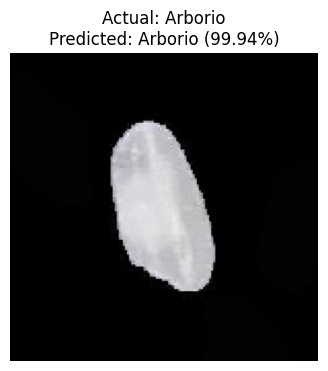

In [9]:
# Ambil 1 sampel gambar dari test set untuk dilakukan prediksi
labels = list(train_generator.class_indices.keys())
sample_class = labels[0]
sample_dir = os.path.join(test_dir, sample_class)
sample_image_name = os.listdir(sample_dir)[0]
sample_image_path = os.path.join(sample_dir, sample_image_name)

img = load_img(sample_image_path, target_size=(150, 150))
img_array = img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0).astype(np.float32)

# Load TFLite Model & Jalankan Inference
interpreter = tf.lite.Interpreter(model_path="tflite/model.tflite")
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

interpreter.set_tensor(input_details[0]['index'], img_array)
interpreter.invoke()

output_data = interpreter.get_tensor(output_details[0]['index'])
predicted_class = labels[np.argmax(output_data[0])]
confidence = np.max(output_data[0]) * 100

# Tampilkan gambar beserta hasil prediksi
plt.figure(figsize=(4, 4))
plt.imshow(img)
plt.axis('off')
plt.title(f"Actual: {sample_class}\nPredicted: {predicted_class} ({confidence:.2f}%)")
plt.show()


In [16]:
import os
import shutil
from google.colab import files

zip_filename = "submission_Endros.zip"
print("1. Menghapus file zip lama (jika ada)...")
if os.path.exists(zip_filename):
    os.remove(zip_filename)

# Memeriksa folder mana saja yang benar-benar ada sebelum dizip
available_dirs = []
for folder in ["saved_model", "tflite", "tfjs_model"]:
    if os.path.exists(folder) and len(os.listdir(folder)) > 0:
        available_dirs.append(folder)
    else:
        print(f"   Peringatan: Folder '{folder}' kosong atau tidak ditemukan.")

print("2. Mengompres folder model yang tersedia...")
if len(available_dirs) > 0:
    # Membuat file zip secara aman menggunakan Python zip
    import zipfile
    with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
        for root_dir in available_dirs:
            for root, dirs, files_in_dir in os.walk(root_dir):
                for file in files_in_dir:
                    file_path = os.path.join(root, file)
                    zipf.write(file_path, os.path.relpath(file_path, '.'))

    size_mb = os.path.getsize(zip_filename) / (1024 * 1024)
    print(f"3. Ukuran Berkas {zip_filename}: {size_mb:.2f} MB")

    print("\n4. Mengunduh berkas ke komputer...")
    files.download(zip_filename)
else:
    print("Error: Tidak ada folder model yang valid untuk dikompres!")

print("\nCatatan: Untuk mengunduh berkas notebook (.ipynb), silakan gunakan menu bawaan di kiri atas Google Colab: File -> Download -> Download .ipynb")
print("SELESAI!")

1. Menghapus file zip lama (jika ada)...
2. Mengompres folder model yang tersedia...
3. Ukuran Berkas submission_Endros.zip: 270.03 MB

4. Mengunduh berkas ke komputer...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Catatan: Untuk mengunduh berkas notebook (.ipynb), silakan gunakan menu bawaan di kiri atas Google Colab: File -> Download -> Download .ipynb
SELESAI!
